In [106]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import geopandas as gpd
import rasterio as rio
import rasterio.plot as rioplot
from rasterio.mask import mask
import simpledbf as dbf
import os
import zipfile 


# Distribución de población
Esta sección se centra en el análisis de la distribución de la población. Contiene subsecciones para descargar datos de GHSL, cargar variables del INEGI y distribuir estas variables de población según la superficie construida, lo que permite un análisis detallado de la demografía en el contexto urbano.

In [39]:
# Directorios y rutas de información 
GHSL_FOLDER_PATH = '../data/input/ghsl'
if not os.path.exists(GHSL_FOLDER_PATH):
    os.makedirs(GHSL_FOLDER_PATH)

SCINCE_FOLDER_PATH = '../data/input/scince'
if not os.path.exists(SCINCE_FOLDER_PATH):
    os.makedirs(SCINCE_FOLDER_PATH)

POP_DISTRIBUTION_OUTPUT_FOLDER = '../data/output/'
if not os.path.exists(POP_DISTRIBUTION_OUTPUT_FOLDER):
    os.makedirs(POP_DISTRIBUTION_OUTPUT_FOLDER)

# Los archivos de manzanas fueron descargados de INEGI y procesados en QGIS para obtener la información de población por manzana para cada municipio.
MANZANAS_FOLDER_PATH = '../data/input/manzanas'
if not os.path.exists(MANZANAS_FOLDER_PATH):
    os.makedirs(MANZANAS_FOLDER_PATH)


In [40]:
# Variable objetivo de INEGI
target_attributes = "POB1"
target_attributes_names = "Población total"

# Clave del municipio considerado para el análisis de brechas de servicios. Es un código de 5 dígitos, donde los dos primeros dígitos corresponden al estado y los tres últimos al municipio.
study_area = '07009'


In [41]:
# Cargar información de municipios de México
municipios = gpd.read_file('../data/input/scince/municipal.shp')
municipios.head(5)

,CVEGEO,NOM_ENT,NOMGEO,POB1,POB2,POB2_R,POB4,POB4_R,POB5,POB5_R,...,POB121,POB121_R,POB122,POB122_R,POB123,POB123_R,POB124,POB124_R,OID,geometry
0,01001,Aguascalientes,Aguascalientes,948990.0,44372.0,4.7,48767.0,5.1,97947.0,10.3,...,8177.0,0.9,5230.0,0.6,2817.0,0.3,2180.0,0.2,1,"POLYGON ((2489072.504 1115771.584, 2489352.774..."
1,01002,Aguascalientes,Asientos,51536.0,3170.0,6.2,3342.0,6.5,6605.0,12.8,...,425.0,0.8,285.0,0.6,217.0,0.4,197.0,0.4,2,"POLYGON ((2494680.261 1141224.505, 2494749.948..."
2,01003,Aguascalientes,Calvillo,58250.0,3159.0,5.4,3530.0,6.1,6748.0,11.6,...,723.0,1.2,529.0,0.9,317.0,0.5,285.0,0.5,3,"POLYGON ((2429607.454 1120262.254, 2429071.902..."
3,01004,Aguascalientes,Cosío,17000.0,1032.0,6.1,1062.0,6.2,2086.0,12.3,...,151.0,0.9,97.0,0.6,51.0,0.3,62.0,0.4,4,"POLYGON ((2470517.824 1155028.588, 2470552.248..."
4,01005,Aguascalientes,Jesús María,129929.0,6945.0,5.4,7998.0,6.2,15597.0,12.0,...,826.0,0.6,530.0,0.4,311.0,0.2,246.0,0.2,5,"POLYGON ((2465526.729 1114740.466, 2465752.546..."


Población total: 41135.0


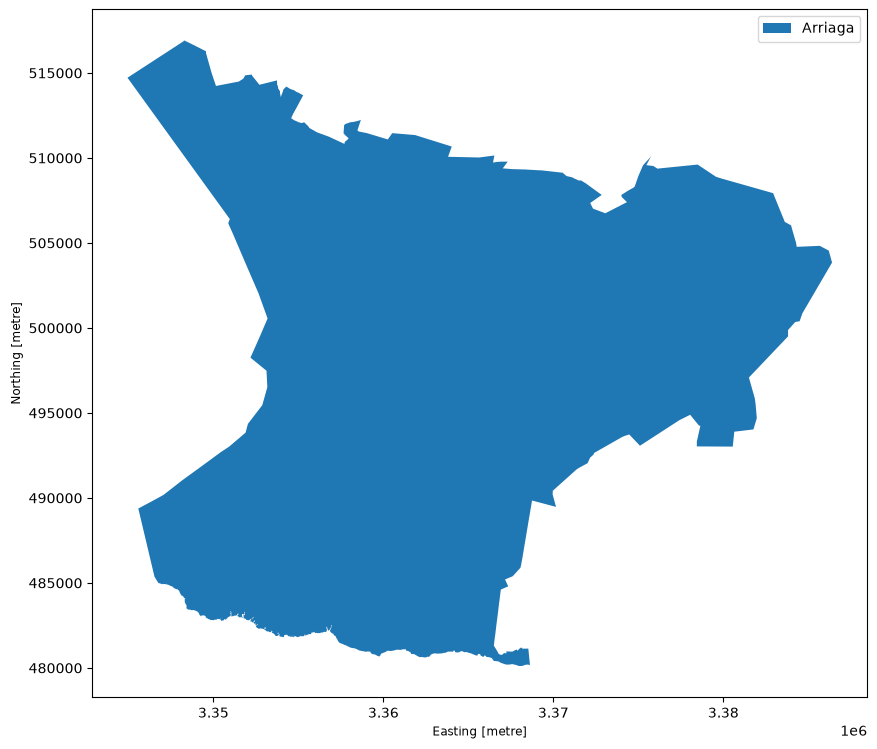

In [49]:
# Filtrar el municipio de estudio
sa_gpd = municipios[municipios['CVEGEO'].isin([study_area])]
sa_gpd.plot(column='NOMGEO', legend=True, figsize=(10, 10))

pob_municipal = sa_gpd['POB1'].values[0]
print("Población total: {}".format(pob_municipal))

In [48]:
manzana_file_paths = os.path.join(MANZANAS_FOLDER_PATH, f"CVEMUN_{study_area}.gpkg")
manzana_gpd = gpd.read_file(manzana_file_paths)

# Estimar la población total por manzanas y compararla con la población total del municipio
pob_manzanas = manzana_gpd['POB1'].sum()
print("Población total por manzanas: {}".format(pob_manzanas))

Población total por manzanas: 28908.0


In [51]:
pob_urbana_ratio = 100 * (pob_manzanas / pob_municipal)
print("Proporción de población por manzanas: {}".format(pob_urbana_ratio))

Proporción de población por manzanas: 70.2759207487541


# GHSL Downloader
Descarga de información de GHSL

In [53]:
# Cargar malla de GHSL 
ghsl_grid = gpd.read_file('../data/input/ghsl/GHSL2_0_MWD_L1_tile_schema_land.shp')
ghsl_grid.head(5)

,tile_id,left,top,right,bottom,geometry
0,R10_C10,-9041000,0,-8041000,-1000000,"POLYGON ((-9041000 0, -8041000 0, -8041000 -10..."
1,R10_C11,-8041000,0,-7041000,-1000000,"POLYGON ((-8041000 0, -7041000 0, -7041000 -10..."
2,R10_C12,-7041000,0,-6041000,-1000000,"POLYGON ((-7041000 0, -6041000 0, -6041000 -10..."
3,R10_C13,-6041000,0,-5041000,-1000000,"POLYGON ((-6041000 0, -5041000 0, -5041000 -10..."
4,R10_C14,-5041000,0,-4041000,-1000000,"POLYGON ((-5041000 0, -4041000 0, -4041000 -10..."


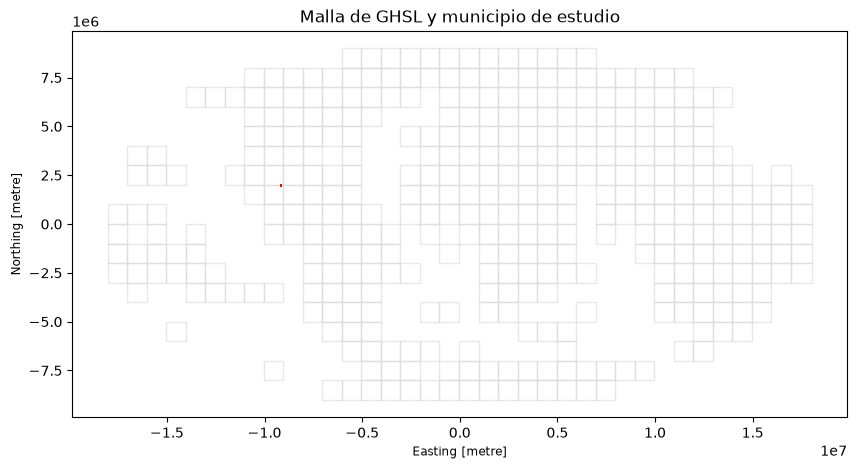

In [71]:
# Proyectar la malla de GHSL al sistema de coordenadas del municipio
sa_gpd_projected = sa_gpd.to_crs(ghsl_grid.crs)

fig, ax = plt.subplots(figsize=(10, 10))
ghsl_grid.plot(ax=ax, color='white', edgecolor='lightgrey', alpha=0.5)
sa_gpd_projected.plot(ax=ax, color='red', edgecolor='red')
plt.title('Malla de GHSL y municipio de estudio')
plt.show()

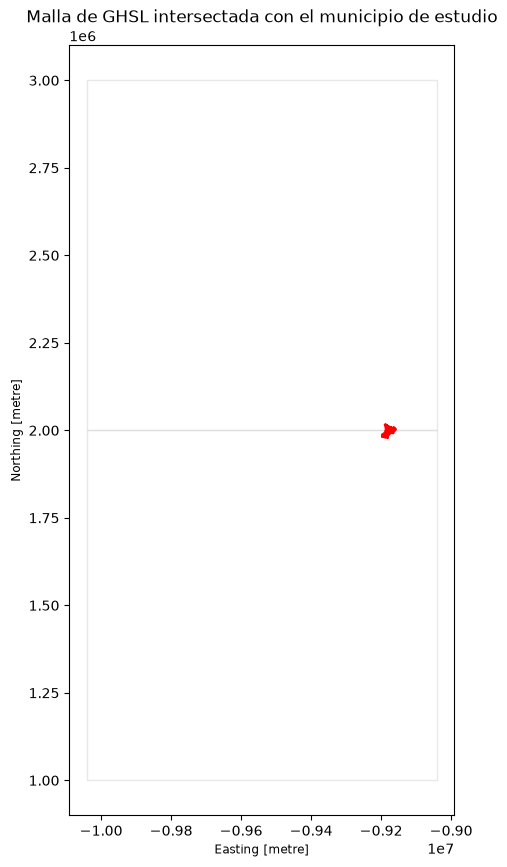

In [75]:
# Seleccionq todas los cuadrantes de la malla de GHSL que intersectan con el municipio de estudio
ghsl_instersected = ghsl_grid.sjoin(sa_gpd_projected, predicate = 'intersects') 
ghsl_instersected

fig, ax = plt.subplots(figsize=(10, 10))
ghsl_instersected.plot(ax=ax, color='white', edgecolor='lightgrey', alpha=0.5)
sa_gpd_projected.plot(ax=ax, color='red', edgecolor='red')
plt.title('Malla de GHSL intersectada con el municipio de estudio')
plt.show()

In [78]:
dataset = "GHS_BUILT_S"
# Define the GHSL URL structure
#base_url <- "https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_C_GLOBE_R2023A/GHS_BUILT_C_MSZ_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/"
base_url = "https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_S_GLOBE_R2023A/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/"

#filename_prefix <- "GHS_BUILT_C_MSZ_E2018_GLOBE_R2023A_54009_10_V1_0_"
filename_prefix = "GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_"

num_features = len(ghsl_instersected)
num_features

# Create destination directory using os


# Iterate through the GeoDataFrame rows
for i, (index, current_feature) in enumerate(ghsl_instersected.iterrows(), start=1):
    
    # Extract the tile ID
    tile_id = current_feature['tile_id']
    
    print(f"\n--- Processing feature # {i} : Tile ID is {tile_id} ---")
    
    # A. Construct Paths
    tile_destination_directory = GHSL_FOLDER_PATH
    
    # Filename and URL strings
    zip_filename = f"{filename_prefix}{tile_id}.zip"
    full_url = f"{base_url}{zip_filename}"
    
    # Use os.path to build the output path
    full_dest_file_path = os.path.join(tile_destination_directory, zip_filename)
    
    # B. Create Destination Folder
    if not os.path.exists(tile_destination_directory):
        os.makedirs(tile_destination_directory, exist_ok=True)
        print(f"Created destination folder at: {tile_destination_directory}")
    else:
        print(f"Destination folder already exists at: {tile_destination_directory}")
    
    # C. Download File using os.system
    if os.path.exists(full_dest_file_path):
        print(f"File already exists. Skipping download for: {zip_filename}")
    else:
        print(f"Starting download of: {full_url}")
        print(f"Saving to: {full_dest_file_path}")
        
        # Executes curl via os.system (mirrors R's libcurl option)
        exit_code = os.system(f'curl -o "{full_dest_file_path}" "{full_url}"')
        
        if exit_code == 0:
            print("Download complete!")
        else:
            print(f"Download failed for URL: {full_url}")


--- Processing feature # 1 : Tile ID is R7_C9 ---
Destination folder already exists at: ../data/input/ghsl
Starting download of: https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_S_GLOBE_R2023A/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
Saving to: ../data/input/ghsl\GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
Download complete!

--- Processing feature # 2 : Tile ID is R8_C9 ---
Destination folder already exists at: ../data/input/ghsl
Starting download of: https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_S_GLOBE_R2023A/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip
Saving to: ../data/input/ghsl\GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip
Download complete!


In [86]:
# D. Identificar y descomprimir todos los archivos ZIP de GHSL_FOLDER_PATH
zip_file_paths = [
    os.path.join(GHSL_FOLDER_PATH, filename)
    for filename in os.listdir(GHSL_FOLDER_PATH)
    if filename.lower().endswith(".zip")
    and os.path.isfile(os.path.join(GHSL_FOLDER_PATH, filename))
]

if not zip_file_paths:
    print(f"No se encontraron archivos ZIP en: {GHSL_FOLDER_PATH}")
else:
    print(f"Se encontraron {len(zip_file_paths)} archivos ZIP:")
    for zip_file_path in zip_file_paths:
        print(f"- {os.path.basename(zip_file_path)}")

    for zip_file_path in zip_file_paths:
        try:
            with zipfile.ZipFile(zip_file_path, "r") as zip_ref:
                zip_ref.extractall(GHSL_FOLDER_PATH)
            print(f"Descomprimido: {os.path.basename(zip_file_path)}")
        except zipfile.BadZipFile:
            print(f"ERROR: El archivo no es un ZIP válido: {zip_file_path}")

Se encontraron 2 archivos ZIP:
- GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
- GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip
Descomprimido: GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
Descomprimido: GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip


# Distribución de población


In [ ]:
tif_files = [f for f in os.listdir(GHSL_FOLDER_PATH) if f.endswith('.tif')]
cropped_rasters = []

for f in tif_files:
    path = os.path.join(GHSL_FOLDER_PATH, f)
    with rio.open(path) as src:
        # Check if study area bounds overlap with tile
        try:
            out_img, out_transform = mask(src, sa_gpd_projected .geometry, crop=True)
            # Only keep non-empty intersections
            if out_img.any():
                cropped_rasters.append(src)
        except ValueError:
            # Bounds do not overlap, skip tile
            continue

In [112]:
import os
import rasterio as rio
from rasterio.mask import mask
from rasterio.merge import merge

# 1. Define your specific list of file paths
file_paths = [
    '../data/input/ghsl/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.tif',
    '../data/input/ghsl/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.tif'
]

cropped_datasets = []
opened_files = []

# 2. Open each file and crop to 'sa' before merging
for fp in file_paths:
    src = rio.open(fp)
    opened_files.append(src)
    
    # Align CRS if necessary
    sa_proj = sa_gpd_projected.to_crs(src.crs) if sa_gpd_projected.crs != src.crs else sa_gpd_projected
    
    try:
        # Crop window to study area
        out_image, out_transform = mask(src, sa_proj.geometry, crop=True)
        
        if out_image.any():
            # Store in-memory raster dataset
            memfile = rio.MemoryFile()
            meta = src.meta.copy()
            meta.update({
                "height": out_image.shape[1],
                "width": out_image.shape[2],
                "transform": out_transform
            })
            ds = memfile.open(**meta)
            ds.write(out_image)
            cropped_datasets.append(ds)
            
    except ValueError:
        # Tile does not overlap study area
        continue

# 3. Perform the mosaic on the cropped datasets
if cropped_datasets:
    mosaic_array, out_transform = merge(cropped_datasets)
    
    # 4. Prepare metadata and save
    out_meta = cropped_datasets[0].meta.copy()
    out_meta.update({
        "driver": "GTiff",
        "height": mosaic_array.shape[1],
        "width": mosaic_array.shape[2],
        "transform": out_transform,
        "compress": "deflate"
    })
    
    output_mosaic_path = '../data/input/ghsl/ghsl_study_area_mosaic.tif'
    with rio.open(output_mosaic_path, "w", **out_meta) as dest:
        dest.write(mosaic_array)
        
    print(f"Mosaic successfully saved to: {output_mosaic_path}")
    
    # Clean up memory datasets
    for ds in cropped_datasets:
        ds.close()
else:
    print("No spatial overlap found between the tiles and the study area.")

# Clean up raw file connections
for src in opened_files:
    src.close()

Mosaic successfully saved to: ../data/input/ghsl/ghsl_study_area_mosaic.tif


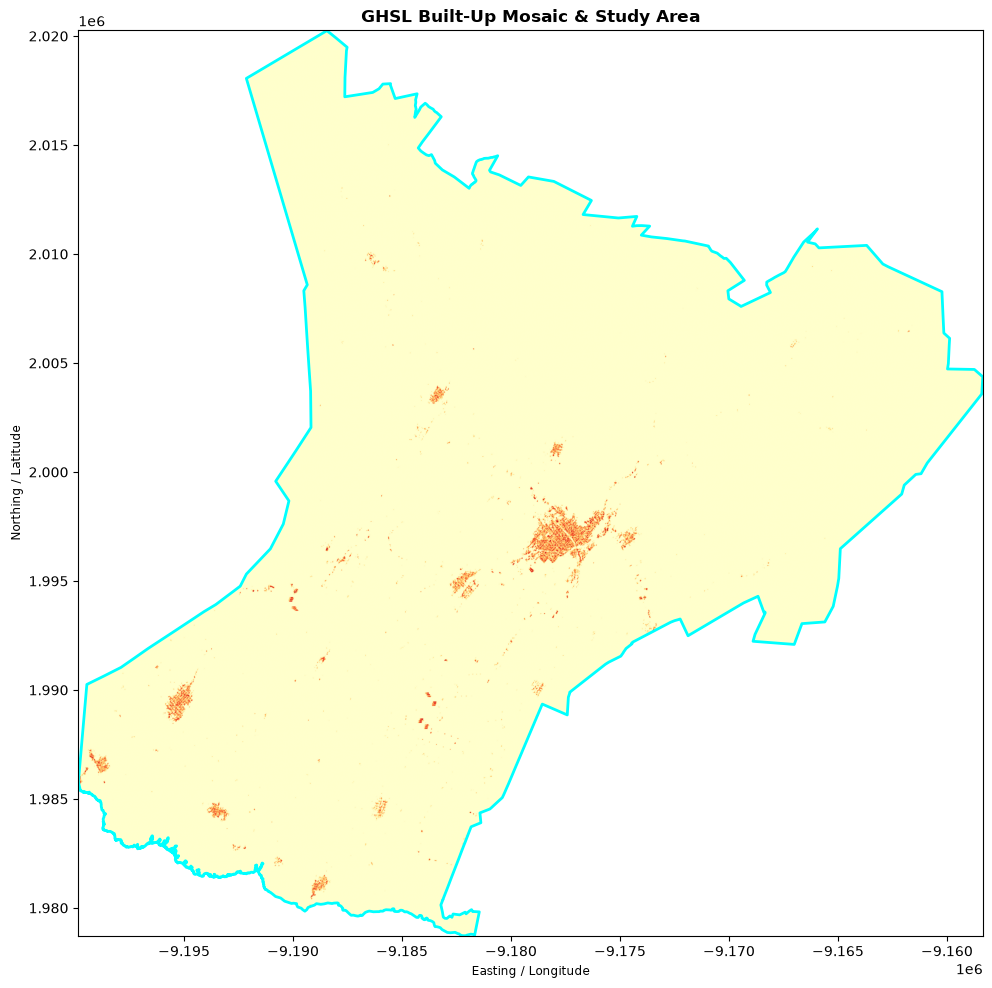

In [114]:
import os
import rasterio as rio
from rasterio.plot import show
import matplotlib.pyplot as plt

mosaic_path = '../data/input/ghsl/ghsl_study_area_mosaic.tif'

with rio.open(mosaic_path) as src:
    # 1. Ensure the study area GeoDataFrame matches the raster's CRS
    sa_proj = sa_gpd_projected.to_crs(src.crs) if sa_gpd_projected.crs != src.crs else sa_gpd_projected

    # 2. Set up Matplotlib figure
    fig, ax = plt.subplots(figsize=(10, 10))

    # 3. Plot the raster mosaic using rasterio's show helper
    # 'cmap' sets color palette (e.g., 'viridis', 'magma', or 'YlOrRd')
    raster_plot = show(src, ax=ax, cmap="YlOrRd", title="GHSL Built-Up Mosaic & Study Area")

    # 4. Overlay the study area boundary polygon
    sa_proj.plot(
        ax=ax, 
        facecolor="none",      # Transparent interior so raster is visible
        edgecolor="cyan",      # High-contrast outline color
        linewidth=2, 
        label="Study Area"
    )

    # 5. Format plot axes and layout
    ax.set_xlabel("Easting / Longitude")
    ax.set_ylabel("Northing / Latitude")
    plt.tight_layout()
    plt.show()